In [9]:
import pandas as pd
import numpy as np

demo = pd.read_sas('../data/DEMO_L.xpt')
bmx = pd.read_sas('../data/BMX_L.xpt')
slq = pd.read_sas('../data/SLQ_L.xpt')

print("DEMO:", demo.shape)
print("BMX:", bmx.shape)
print("SLQ:", slq.shape)

DEMO: (11933, 27)
BMX: (8860, 22)
SLQ: (8501, 7)


C:\Users\cebit.ir\AppData\Local\Temp\ipykernel_21740\2475134195.py:6: Pandas4Warning: The default value of 'encoding' in read_sas is deprecated. In a future version the default will change from None to 'infer', and character columns will be decoded rather than returned as bytes (XPORT files record no encoding, so 'infer' means 'ISO-8859-1'). Pass encoding='infer' to adopt the future behavior, or encoding=None to keep the current one.
  slq = pd.read_sas('../data/SLQ_L.xpt')


In [10]:
cols_demo = ['SEQN', 'RIAGENDR', 'RIDAGEYR', 'WTMEC2YR']
cols_bmx = ['SEQN', 'BMXBMI']
cols_slq = ['SEQN', 'SLD012']

df = demo[cols_demo].merge(bmx[cols_bmx], on='SEQN', how='inner')
df = df.merge(slq[cols_slq], on='SEQN', how='inner')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6615 entries, 0 to 6614
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      6615 non-null   float64
 1   RIAGENDR  6615 non-null   float64
 2   RIDAGEYR  6615 non-null   float64
 3   WTMEC2YR  6615 non-null   float64
 4   BMXBMI    6512 non-null   float64
 5   SLD012    6550 non-null   float64
dtypes: float64(6)
memory usage: 310.2 KB


In [11]:
print(df.isna().sum())

df = df[df['RIDAGEYR'] >= 20]
df_clean = df.dropna(subset=['BMXBMI', 'SLD012']).copy()

print(len(df_clean))

SEQN          0
RIAGENDR      0
RIDAGEYR      0
WTMEC2YR      0
BMXBMI      103
SLD012       65
dtype: int64
5910


In [12]:
df_clean.to_csv('../data/cleaned_nhanes.csv', index=False)
df_clean.head()

,SEQN,RIAGENDR,RIDAGEYR,WTMEC2YR,BMXBMI,SLD012
0,130378.0,1.0,43.0,54374.463898,27.0,9.5
1,130379.0,1.0,66.0,34084.721548,33.5,9.0
2,130380.0,2.0,44.0,81196.277992,29.7,8.0
3,130386.0,1.0,34.0,39988.452940,30.2,7.5
4,130387.0,2.0,68.0,20776.254850,42.6,3.0


In [13]:
vars_of_interest = ['RIDAGEYR', 'BMXBMI', 'SLD012']
stats = df_clean[vars_of_interest].describe().T
stats['median'] = df_clean[vars_of_interest].median()
stats['iqr'] = stats['75%'] - stats['25%']

stats[['count', 'mean', 'std', 'median', 'iqr', 'min', 'max']].round(2)

,count,mean,std,median,iqr,min,max
RIDAGEYR,5910.0,53.72,17.16,57.0,29.0,20.0,80.0
BMXBMI,5910.0,29.83,7.36,28.5,8.9,11.1,74.8
SLD012,5910.0,7.70,1.58,8.0,1.5,2.0,14.0


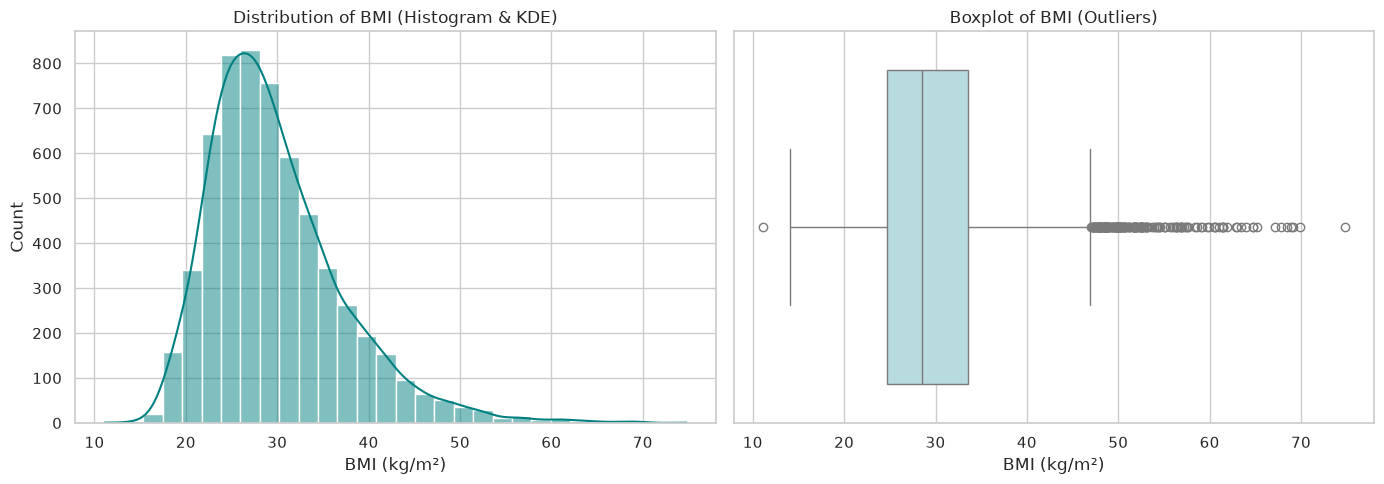

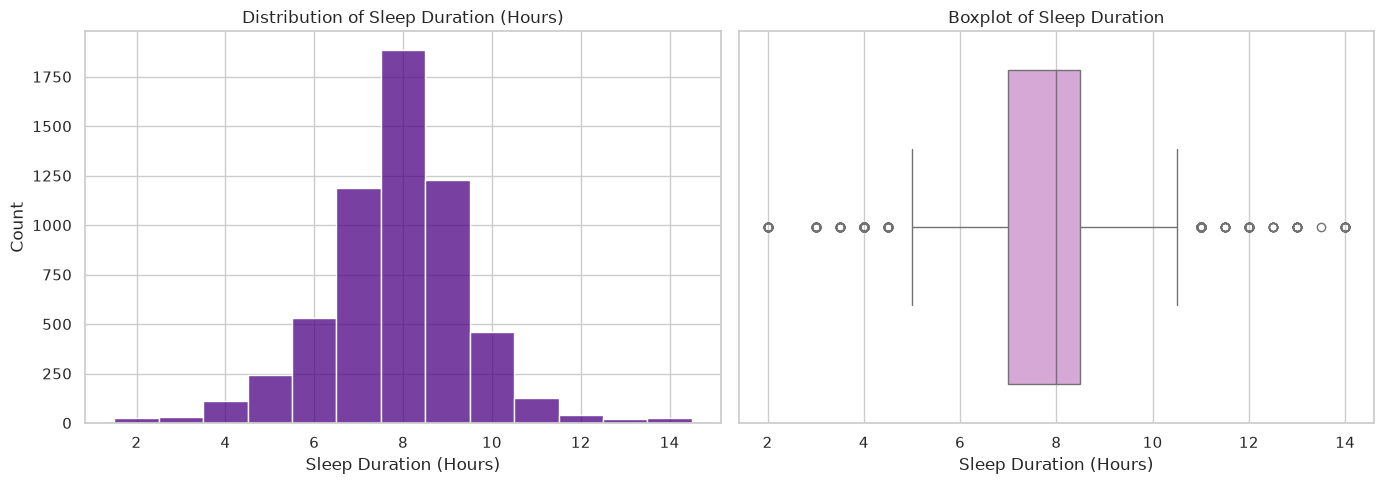

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean['BMXBMI'], kde=True, ax=axes[0], color='teal', bins=30)
axes[0].set_title('Distribution of BMI (Histogram & KDE)', fontsize=12)
axes[0].set_xlabel('BMI (kg/m²)')
axes[0].set_ylabel('Count')

sns.boxplot(x=df_clean['BMXBMI'], ax=axes[1], color='powderblue')
axes[1].set_title('Boxplot of BMI (Outliers)', fontsize=12)
axes[1].set_xlabel('BMI (kg/m²)')

plt.tight_layout()
plt.savefig('../figures/bmi_distribution.png', dpi=300)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean['SLD012'], discrete=True, ax=axes[0], color='indigo')
axes[0].set_title('Distribution of Sleep Duration (Hours)', fontsize=12)
axes[0].set_xlabel('Sleep Duration (Hours)')
axes[0].set_ylabel('Count')

sns.boxplot(x=df_clean['SLD012'], ax=axes[1], color='plum')
axes[1].set_title('Boxplot of Sleep Duration', fontsize=12)
axes[1].set_xlabel('Sleep Duration (Hours)')

plt.tight_layout()
plt.savefig('../figures/sleep_distribution.png', dpi=300)
plt.show()